# Mental disorders, daily-life interference, and reported care

Judy Chen — Milestone 2 working notebook

**Status: starter in progress.** Figures 1–4 are implemented below. Figures 5–13 have
their questions and preparation notes in place, but their plotting cells are not yet implemented.
The completed draft will select 8–12 images from the 13-figure development set.

**Main question:** How did reported mental-health care vary by disorder type and
interference with daily life among U.S. adults in 2001–2003?

**Contemporary question:** Among adults with a past-year major depressive episode in
2024, how did depression-related care vary with severe role impairment and insurance coverage?

Run cells from top to bottom. See [README.md](README.md) for environment and local-data setup,
and [static-draft.md](static-draft.md) for the draft write-up and image descriptions.


## 1. Imports, paths, and custom theme

The two respondent-level source files remain local. By default, put them in this
folder's ignored `data/` directory; environment variables can point to files elsewhere.
This notebook exports only aggregate figures and displays aggregate checks.


In [1]:
from pathlib import Path
import csv
import io
import os
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t
from IPython.display import display

candidates = [
    Path.cwd(),
    Path.cwd() / "milestone2_draft",
    Path.cwd() / "static-viz-project" / "milestone2_draft",
]
DRAFT_DIR = next(
    (path for path in candidates if (path / "static-draft.ipynb").is_file()),
    None,
)
if DRAFT_DIR is None:
    raise FileNotFoundError("Open this notebook from the course repository or its draft folder.")

DATA_DIR = Path(os.environ.get("MENTAL_HEALTH_DATA_DIR", DRAFT_DIR / "data")).expanduser()
CPES_PATH = Path(os.environ.get("CPES_DATA_PATH", DATA_DIR / "20240-0001-Data.dta")).expanduser()
NSDUH_PATH = Path(os.environ.get("NSDUH_DATA_PATH", DATA_DIR / "nsduh2024.zip")).expanduser()
FIGURE_DIR = DRAFT_DIR / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

missing_files = [path.name for path in (CPES_PATH, NSDUH_PATH) if not path.is_file()]
if missing_files:
    raise FileNotFoundError(
        "Missing local survey files: " + ", ".join(missing_files)
        + ". Follow the data setup in README.md. Raw data are intentionally absent from GitHub."
    )

BG, INK, MUTED = "#FAF7F1", "#25343C", "#5F6B70"
TEAL, GOLD, GRID = "#247C78", "#C78D36", "#DCDCD4"
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "figure.facecolor": BG,
    "axes.facecolor": BG,
    "savefig.facecolor": BG,
    "text.color": INK,
    "axes.labelcolor": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.spines.bottom": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 15,
    "svg.fonttype": "none",
})

def finish_figure(fig, filename, source_note):
    """Save a named, aggregate-only figure and show the same figure in the notebook."""
    fig.text(0.02, 0.02, source_note, fontsize=9, color=MUTED, va="bottom")
    fig.savefig(FIGURE_DIR / filename, dpi=170, bbox_inches="tight")
    plt.show()
    plt.close(fig)


Matplotlib is building the font cache; this may take a moment.


## 2. Source variables and eligible populations

CPES's combined public-use file contains **20,013 rows and 5,543 columns**.
The shared analysis pool uses the official NCS-R Part 2 + NLAAS weight, `NCNLWTLG`,
and contains **10,341 respondents**. The six disorder groups overlap.

NSDUH 2024 contains **58,633 rows and 2,632 columns**, including **47,299 adults**.
Its contemporary section is separate from CPES; differences in instruments and classifications
do not support a direct historical trend.


In [2]:
DISORDERS = {
    "Major depressive disorder": {
        "diagnosis": "V07655", "social": "V00992",
        "domains": ["V00989", "V00991", "V00992"],
        "professional_care": "V01013", "ever_help": "V00999",
    },
    "Generalized anxiety disorder": {
        "diagnosis": "V07613", "social": "V01870",
        "domains": ["V01867", "V01869", "V01870"],
        "professional_care": "V01891", "ever_help": "V01874",
    },
    "Panic disorder": {
        "diagnosis": "V07716", "social": "V01353",
        "domains": ["V01350", "V01352", "V01353"],
        "professional_care": "V01394", "ever_help": "V01359",
    },
    "Social phobia": {
        "diagnosis": "V07748", "social": "V01579",
        "domains": ["V01576", "V01578", "V01579"],
        "professional_care": "V01621", "ever_help": "V01583",
    },
    "Agoraphobia without panic disorder": {
        "diagnosis": "V07513", "social": "V01692",
        "domains": ["V01689", "V01691", "V01692"],
        "professional_care": "V01734", "ever_help": "V01694",
    },
    "PTSD": {
        "diagnosis": "V07725", "social": "V04037",
        "domains": ["V04034", "V04036", "V04037"],
        "professional_care": "V04040", "ever_help": "V03963",
    },
}
MEDICATIONS = {
    "Antidepressants": "V02614", "Tranquilizers": "V02616",
    "Stimulants": "V02617", "Antipsychotics": "V02620",
    "Sleeping pills/sedatives": "V02807",
}
cpes_columns = {"CPESCASE", "CPESPROJ", "NCNLWTLG", "SESTRAT", "SECLUSTR"}
for spec in DISORDERS.values():
    cpes_columns.update([
        spec["diagnosis"], spec["social"], spec["professional_care"], spec["ever_help"],
        *spec["domains"],
    ])
cpes_columns.update(MEDICATIONS.values())

with pd.io.stata.StataReader(CPES_PATH, convert_categoricals=False) as reader:
    cpes_labels = reader.variable_labels()
    cpes_source_rows = int(reader._nobs)
    cpes_source_columns = len(cpes_labels)
cpes_raw = pd.read_stata(CPES_PATH, columns=sorted(cpes_columns), convert_categoricals=False)
cpes = cpes_raw.loc[cpes_raw["NCNLWTLG"].gt(0)].copy()
assert cpes_source_rows == 20_013 and cpes_source_columns == 5_543
assert cpes_raw["CPESCASE"].nunique() == 20_013 and len(cpes) == 10_341

nsduh_columns = [
    "IRAMDEYR", "IRAMDEIMP", "ATXMDEYR", "ARXMDEYR", "AMDETXRX",
    "ANALWT2_C", "VESTR_C", "VEREP", "IRINSUR4", "AGE3", "INCOME", "POVERTY3",
]
with zipfile.ZipFile(NSDUH_PATH) as archive:
    with archive.open("NSDUH_2024_Tab.txt") as stream:
        nsduh_source_columns = len(next(csv.reader(io.TextIOWrapper(stream), delimiter="\t")))
    with archive.open("NSDUH_2024_Tab.txt") as stream:
        nsduh_raw = pd.read_csv(stream, sep="\t", usecols=nsduh_columns, na_values=["."])
assert len(nsduh_raw) == 58_633 and nsduh_source_columns == 2_632
nsduh_adults = nsduh_raw.loc[nsduh_raw["IRAMDEYR"].isin([0, 1])].copy()
nsduh_mde = nsduh_adults.loc[nsduh_adults["IRAMDEYR"].eq(1)].copy()
care_known = nsduh_mde["ATXMDEYR"].isin([0, 1]) & nsduh_mde["ARXMDEYR"].isin([0, 1])
nsduh_care = nsduh_mde.loc[care_known].copy()
nsduh_care["care_group"] = np.select([
    nsduh_care["ATXMDEYR"].eq(1) & nsduh_care["ARXMDEYR"].eq(1),
    nsduh_care["ATXMDEYR"].eq(1),
    nsduh_care["ARXMDEYR"].eq(1),
], ["Both", "Professional contact only", "Medication only"], default="Neither reported")
nsduh_care["reported_either"] = nsduh_care["ATXMDEYR"].eq(1) | nsduh_care["ARXMDEYR"].eq(1)
assert len(nsduh_adults) == 47_299 and len(nsduh_mde) == 5_205
assert len(nsduh_care) == 5_008 and (~care_known).sum() == 197

source_summary = pd.DataFrame([
    ["CPES 2001–2003", cpes_source_rows, cpes_source_columns, len(cpes)],
    ["NSDUH 2024", len(nsduh_raw), nsduh_source_columns, len(nsduh_adults)],
], columns=["Source", "Full source rows", "Full source columns", "Adult analysis pool"])
display(source_summary)


,Source,Full source rows,Full source columns,Adult analysis pool
0,CPES 2001–2003,20013,5543,10341
1,NSDUH 2024,58633,2632,47299


## 3. Shared statistical helpers

Estimates use the released survey weights. For a ratio/mean, the helper below uses
Taylor linearization with strata and clusters, a with-replacement variance estimate,
and a t critical value based on the design degrees of freedom. Subgroup calculations retain
the full analysis-pool design and give non-domain observations zero linearized contribution.
No finite-population correction is available here. Weighted boxplot quantiles are descriptive.


In [3]:
def survey_mean(frame, values, domain=None, *, weight, strata, cluster):
    """Estimate a domain mean/ratio and its design-based standard error."""
    y = pd.Series(values, index=frame.index, dtype=float)
    active = y.notna()
    if domain is not None:
        active &= pd.Series(domain, index=frame.index).fillna(False).astype(bool)
    w = frame[weight].astype(float)
    if not np.isfinite(w).all() or not w.gt(0).all():
        raise ValueError("Use a full analysis pool with finite, positive survey weights.")
    if frame[[strata, cluster]].isna().any().any():
        raise ValueError("Missing survey design identifiers need investigation.")
    denominator = w.loc[active].sum()
    if denominator <= 0:
        raise ValueError("No valid weighted observations in the requested domain.")
    estimate = float(np.average(y.loc[active], weights=w.loc[active]))
    residual = (y - estimate).where(active, 0.0)
    design = frame[[strata, cluster]].copy()
    design["linearized"] = w * residual / denominator
    psu_totals = design.groupby([strata, cluster], observed=True)["linearized"].sum()
    components = psu_totals.groupby(level=0).agg(["count", "sum"])
    if components["count"].lt(2).any():
        raise ValueError("A single-PSU stratum needs a documented variance treatment.")
    centered = psu_totals - psu_totals.groupby(level=0).transform("mean")
    square_sums = centered.pow(2).groupby(level=0).sum()
    m = components["count"]
    variance = float((m / (m - 1) * square_sums).sum())
    se = float(np.sqrt(max(variance, 0)))
    degrees_freedom = int((m - 1).sum())
    critical = float(t.ppf(0.975, degrees_freedom))
    return {
        "estimate": estimate, "se": se,
        "lower": estimate - critical * se, "upper": estimate + critical * se,
        "n": int(active.sum()), "design_df": degrees_freedom,
    }

CPES_DESIGN = {"weight": "NCNLWTLG", "strata": "SESTRAT", "cluster": "SECLUSTR"}
NSDUH_DESIGN = {"weight": "ANALWT2_C", "strata": "VESTR_C", "cluster": "VEREP"}

def weighted_quantiles(values, weights, probabilities):
    values, weights = np.asarray(values), np.asarray(weights)
    valid = np.isfinite(values) & np.isfinite(weights) & (weights > 0)
    values, weights = values[valid], weights[valid]
    order = np.argsort(values, kind="stable")
    values, weights = values[order], weights[order]
    cumulative = np.cumsum(weights)
    positions = np.searchsorted(cumulative, np.asarray(probabilities) * cumulative[-1])
    return values[np.clip(positions, 0, len(values) - 1)]


## 4. Figure development

The first four figures use actual CPES responses and the official paired weight.
They are initial drafts for review. Later sections are clearly marked planned; no mock
observations or placeholder graphics are generated for them.


## Figure 01. Prevalence of selected disorders

**Ranked bars · CPES · Implemented**

Which selected disorders were most common?

The denominator is the shared 10,341-person pool. Disorder groups overlap.


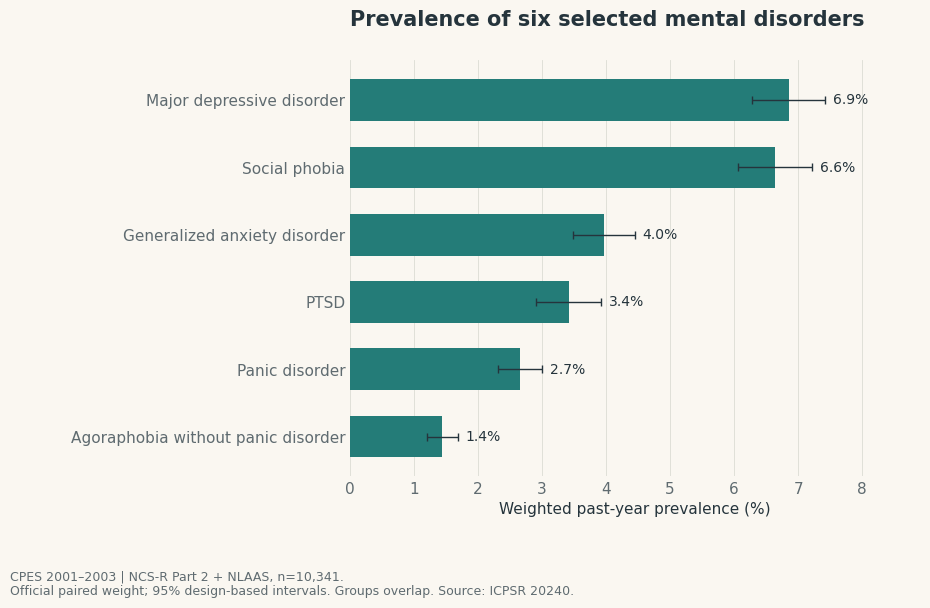

In [4]:
prevalence_rows = []
for name, spec in DISORDERS.items():
    values = cpes[spec["diagnosis"]].map({1: 1.0, 5: 0.0})
    result = survey_mean(cpes, values, **CPES_DESIGN)
    prevalence_rows.append({"Disorder": name, **result})
prevalence = pd.DataFrame(prevalence_rows).sort_values("estimate")

fig, ax = plt.subplots(figsize=(10, 6.4))
fig.subplots_adjust(left=0.36, right=0.93, top=0.86, bottom=0.21)
y = np.arange(len(prevalence))
ax.barh(y, prevalence["estimate"] * 100, color=TEAL, height=0.62)
lower = np.maximum(prevalence["lower"].to_numpy(), 0) * 100
upper = np.minimum(prevalence["upper"].to_numpy(), 1) * 100
estimate = prevalence["estimate"].to_numpy() * 100
ax.errorbar(estimate, y, xerr=[estimate-lower, upper-estimate],
            fmt="none", ecolor=INK, capsize=3, linewidth=1)
ax.set_yticks(y, prevalence["Disorder"])
ax.set_xlim(0, max(upper) * 1.2)
ax.set_xlabel("Weighted past-year prevalence (%)")
ax.set_title("Prevalence of six selected mental disorders", loc="left", pad=25)
ax.xaxis.grid(True, color=GRID, linewidth=0.6)
ax.set_axisbelow(True)
ax.tick_params(length=0)
for yy, value, high in zip(y, estimate, upper):
    ax.text(high + 0.12, yy, f"{value:.1f}%", va="center", fontsize=10)
finish_figure(fig, "01_prevalence.png",
              "CPES 2001–2003 | NCS-R Part 2 + NLAAS, n=10,341.\n"
              "Official paired weight; 95% design-based intervals. Groups overlap. Source: ICPSR 20240.")


## Figure 02. Pairwise co-occurrence

**Conditional heatmap · CPES · Implemented**

Among adults with one disorder, how often was another present?

Read each row as a conditional percentage; the matrix need not be symmetric.


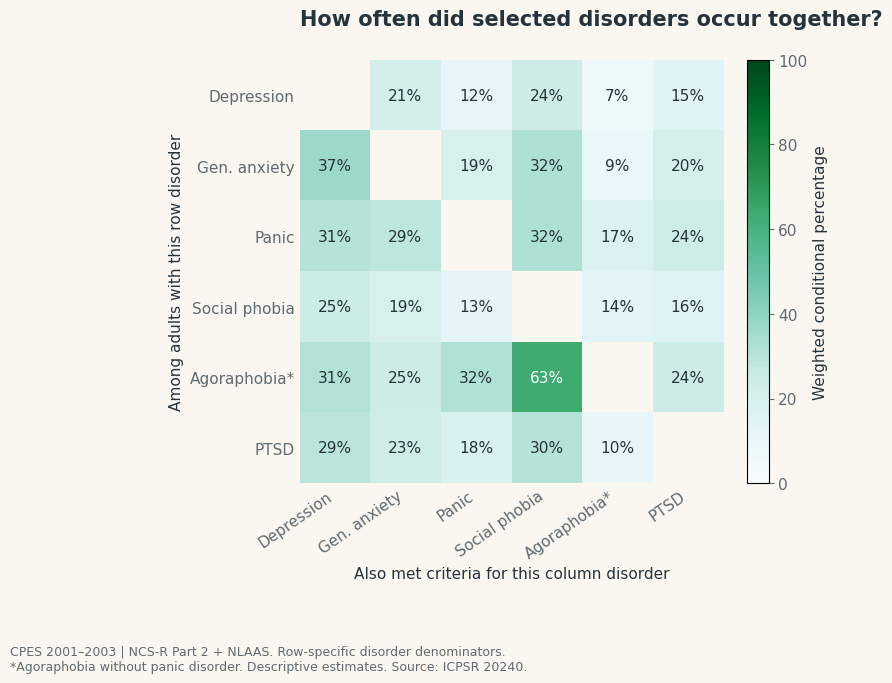

In [5]:
names = list(DISORDERS)
labels_short = ["Depression", "Gen. anxiety", "Panic", "Social phobia", "Agoraphobia*", "PTSD"]
diagnosis_columns = [spec["diagnosis"] for spec in DISORDERS.values()]
flags = cpes[diagnosis_columns].eq(1).to_numpy()
w = cpes["NCNLWTLG"].to_numpy()
cooccurrence = np.full((6, 6), np.nan)
for row in range(6):
    for col in range(6):
        if row != col:
            cooccurrence[row, col] = np.average(flags[flags[:, row], col], weights=w[flags[:, row]]) * 100

fig, ax = plt.subplots(figsize=(9, 7.3))
fig.subplots_adjust(left=0.19, right=0.87, bottom=0.28, top=0.86)
image = ax.imshow(cooccurrence, cmap="BuGn", vmin=0, vmax=100)
for row in range(6):
    for col in range(6):
        if row != col:
            value = cooccurrence[row, col]
            ax.text(col, row, f"{value:.0f}%", ha="center", va="center",
                    color="white" if value > 60 else INK, fontsize=11)
ax.set_xticks(range(6), labels_short, rotation=35, ha="right")
ax.set_yticks(range(6), labels_short)
ax.set_xlabel("Also met criteria for this column disorder")
ax.set_ylabel("Among adults with this row disorder")
ax.set_title("How often did selected disorders occur together?", loc="left", pad=25)
ax.tick_params(length=0)
fig.colorbar(image, ax=ax, fraction=0.045, pad=0.04, label="Weighted conditional percentage")
finish_figure(fig, "02_cooccurrence_heatmap.png",
              "CPES 2001–2003 | NCS-R Part 2 + NLAAS. Row-specific disorder denominators.\n"
              "*Agoraphobia without panic disorder. Descriptive estimates. Source: ICPSR 20240.")


## Figure 03. Exact disorder combinations

**UpSet plot · CPES · Implemented**

Which exact combinations of the six selected disorders were most common?

Colored dots in one column identify an exact combination. Its line joins the included disorders; gray dots are not included.


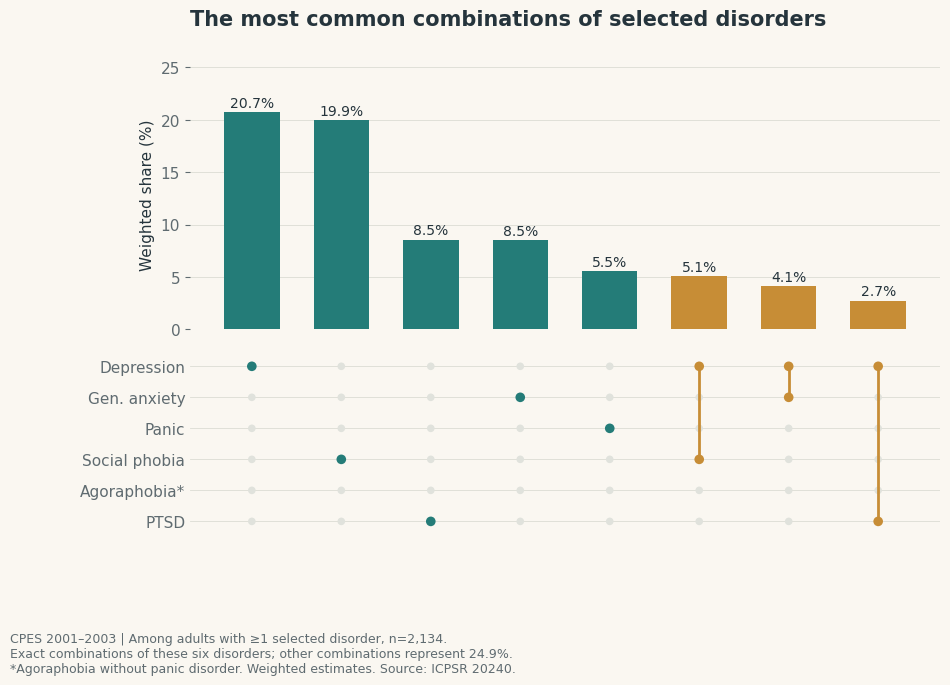

In [6]:
diagnosis_columns = [spec["diagnosis"] for spec in DISORDERS.values()]
valid_diagnoses = cpes[diagnosis_columns].isin([1, 5]).all(axis=1)
assert valid_diagnoses.all(), "Resolve missing diagnostic flags before defining exact combinations."
bits = cpes[diagnosis_columns].eq(1).to_numpy().astype(int)
pattern = (bits * (2 ** np.arange(6))).sum(axis=1)
pattern_weights = pd.DataFrame({"pattern": pattern, "weight": cpes["NCNLWTLG"].to_numpy()}).groupby("pattern")["weight"].sum()
positive = pattern_weights.loc[pattern_weights.index > 0]
top_patterns = positive.sort_values(ascending=False).head(8)
shares = top_patterns / positive.sum() * 100
omitted_share = 100 - shares.sum()
any_disorder_n = int((pattern > 0).sum())
assert any_disorder_n == 2_134

fig = plt.figure(figsize=(10, 7.5))
grid = fig.add_gridspec(2, 1, left=0.20, right=0.95, top=0.84,
                        bottom=0.20, height_ratios=[1.4, 1], hspace=0.08)
top_ax = fig.add_subplot(grid[0])
matrix_ax = fig.add_subplot(grid[1], sharex=top_ax)
x = np.arange(len(shares))
colors = [GOLD if int(p).bit_count() > 1 else TEAL for p in shares.index]
top_ax.bar(x, shares.to_numpy(), color=colors, width=0.62)
top_ax.set_ylim(0, shares.max() * 1.24)
top_ax.set_ylabel("Weighted share (%)")
top_ax.set_title("The most common combinations of selected disorders", loc="left", pad=25)
top_ax.yaxis.grid(True, color=GRID, linewidth=0.6)
top_ax.set_axisbelow(True)
top_ax.tick_params(axis="x", bottom=False, labelbottom=False)
for xx, value in zip(x, shares):
    top_ax.text(xx, value+0.5, f"{value:.1f}%", ha="center", fontsize=10)
for row in range(6):
    matrix_ax.axhline(row, color=GRID, linewidth=0.6, zorder=0)
    matrix_ax.scatter(x, np.repeat(row, len(x)), color="#E0E2DC", s=30, edgecolors="none")
for col, p in enumerate(shares.index):
    active = [row for row in range(6) if int(p) & (2 ** row)]
    if len(active) > 1:
        matrix_ax.plot([col, col], [min(active), max(active)], color=colors[col], linewidth=2)
    matrix_ax.scatter(np.repeat(col, len(active)), active, color=colors[col], s=48, edgecolors="none", zorder=3)
matrix_ax.set_yticks(range(6), labels_short)
matrix_ax.set_ylim(5.6, -0.6)
matrix_ax.set_xticks([])
matrix_ax.tick_params(length=0)
finish_figure(fig, "03_upset.png",
              f"CPES 2001–2003 | Among adults with ≥1 selected disorder, n={any_disorder_n:,}.\n"
              f"Exact combinations of these six disorders; other combinations represent {omitted_share:.1f}%.\n"
              "*Agoraphobia without panic disorder. Weighted estimates. Source: ICPSR 20240.")


## Figure 04. Social-life interference

**Weighted boxplots · CPES · Implemented**

How did the distribution of social-life interference differ across disorders?

Use only scores from 0 to 10. Boxes show weighted quartiles and whiskers show weighted 5th–95th percentiles.


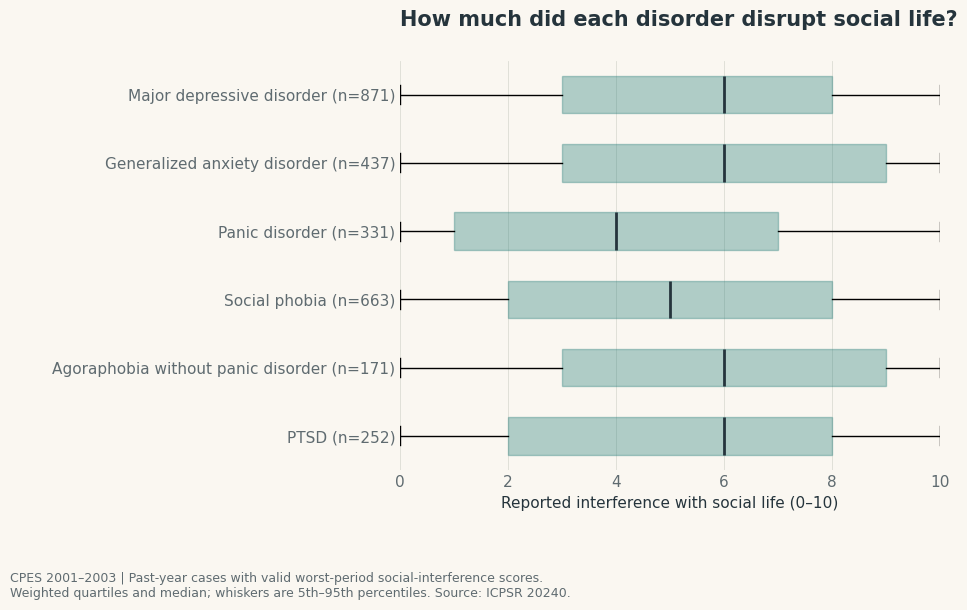

In [7]:
box_stats = []
box_labels = []
for name, spec in DISORDERS.items():
    valid = cpes[spec["diagnosis"]].eq(1) & cpes[spec["social"]].between(0, 10)
    q05, q25, q50, q75, q95 = weighted_quantiles(
        cpes.loc[valid, spec["social"]], cpes.loc[valid, "NCNLWTLG"],
        [0.05, 0.25, 0.50, 0.75, 0.95],
    )
    box_stats.append({"whislo": q05, "q1": q25, "med": q50, "q3": q75, "whishi": q95, "fliers": []})
    box_labels.append(f"{name} (n={valid.sum():,})")
fig, ax = plt.subplots(figsize=(10, 6.5))
fig.subplots_adjust(left=0.41, right=0.95, top=0.85, bottom=0.22)
artists = ax.bxp(box_stats, orientation="horizontal", patch_artist=True, widths=0.55, showfliers=False)
for box in artists["boxes"]:
    box.set(facecolor=TEAL, edgecolor=TEAL, alpha=0.35)
for median in artists["medians"]:
    median.set(color=INK, linewidth=2)
ax.set_yticks(np.arange(1, 7), box_labels)
ax.invert_yaxis()
ax.set_xlim(0, 10)
ax.set_xticks([0, 2, 4, 6, 8, 10])
ax.set_xlabel("Reported interference with social life (0–10)")
ax.set_title("How much did each disorder disrupt social life?", loc="left", pad=25)
ax.xaxis.grid(True, color=GRID, linewidth=0.6)
ax.set_axisbelow(True)
ax.tick_params(length=0)
finish_figure(fig, "04_social_interference_boxplots.png",
              "CPES 2001–2003 | Past-year cases with valid worst-period social-interference scores.\n"
              "Weighted quartiles and median; whiskers are 5th–95th percentiles. Source: ICPSR 20240.")


## Figure 05. Domains of daily-life interference

**Heatmap · CPES · Planned**

How did home management, relationships, and social-life interference compare?

Use home management, close relationships, and social life, with valid scores in all three domains within each disorder. Verify the source labels before plotting.


In [8]:
# Figure 05: planned.
# Add validated plotting code here; no placeholder observations or graphic are generated.


## Figure 06. Disorder-specific professional care

**Dot-and-interval plot · CPES · Planned**

What share of each disorder group reported professional help for that disorder?

**Preparation needed:** reconstruct disorder-specific treatment skips. Missing follow-up responses must not automatically become no care.


In [9]:
# Figure 06: planned.
# Add validated plotting code here; no placeholder observations or graphic are generated.


## Figure 07. Reported medication classes

**Heatmap · CPES · Planned**

Which medication classes did adults in each disorder group report?

Medication classes overlap. Report use among people with a disorder without assuming the prescribing indication.


In [10]:
# Figure 07: planned.
# Add validated plotting code here; no placeholder observations or graphic are generated.


## Figure 08. Interference and antidepressant use

**Point-and-line plot · CPES · Planned**

Within depression, how did antidepressant use vary across interference bands?

Use score bands 0–3, 4–6, and 7–10 in the 868-person joint-response depression subgroup. These are numerical bands, not universal clinical severity labels.


In [11]:
# Figure 08: planned.
# Add validated plotting code here; no placeholder observations or graphic are generated.


## Figure 09. Burden and professional care

**Scatterplot · CPES · Planned**

Did greater average social-life interference coincide with more reported care?

**Preparation needed:** reconstruct disorder-specific treatment skips. Missing follow-up responses must not automatically become no care.


In [12]:
# Figure 09: planned.
# Add validated plotting code here; no placeholder observations or graphic are generated.


## Figure 10. Depression-related care combinations in 2024

**100% stacked bars · NSDUH · Planned**

How did professional contact and medication combinations vary with severe impairment?

Use the four mutually exclusive `care_group` categories. Professional contact is not necessarily psychotherapy.


In [13]:
# Figure 10: planned.
# Add validated plotting code here; no placeholder observations or graphic are generated.


## Figure 11. Impairment, insurance, and reported care

**Alluvial diagram · NSDUH · Planned**

How did impairment, insurance, and care categories occur together?

Use impairment → insurance → either reported care form/neither, conserving weighted shares across all three columns. These categories are not a treatment sequence.


In [14]:
# Figure 11: planned.
# Add validated plotting code here; no placeholder observations or graphic are generated.


## Figure 12. Insurance differences in reported care

**Dot-and-interval plot · NSDUH · Planned**

Among adults with severe impairment, did neither-care rates differ by insurance?

Restrict to adults with severe role impairment and known care responses. Compare insured and uninsured groups descriptively, without a causal claim.


In [15]:
# Figure 12: planned.
# Add validated plotting code here; no placeholder observations or graphic are generated.


## Figure 13. Care out of 100

**Waffle chart · NSDUH · Planned**

What share of the severe-impairment group reported neither care form?

Use two colors for at least one care form versus neither; each square represents about one percentage point. Show the exact estimate and unknown-response count alongside the rounded squares.


In [16]:
# Figure 13: planned.
# Add validated plotting code here; no placeholder observations or graphic are generated.


## Sources and remaining checks

- [CPES study 20240 and documentation](https://www.icpsr.umich.edu/web/ICPSR/studies/20240)
- [NSDUH 2024 data and documentation](https://www.samhsa.gov/data/data-we-collect/nsduh-national-survey-drug-use-and-health/datafiles/2024)

Before the full draft: resolve CPES treatment skips; check domain-question labels and missingness;
complete Figures 5–13 with design-based uncertainty where relevant; reconcile the NSDUH care figures;
and select 8–12 images with at least five distinct types. A lack of these reported care forms
alone does not establish unmet need or treatment effectiveness.
